In [1]:
# Descarga del módulo compartido desde el repositorio de GitHub
from pathlib import Path
from urllib.request import urlretrieve

URL_MODULO = "https://raw.githubusercontent.com/juiturriaga/clasificacion-dbt-deep-learning/refs/heads/main/MNIST/preparar_datos.py"

if not Path("preparar_datos.py").is_file():
    urlretrieve(URL_MODULO, "preparar_datos.py")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Información de las particiones: {'n_train': 9776, 'n_val': 2095, 'n_test': 2095, 'clase_0': 3, 'clase_1': 8, 'semilla': 42}
Entrenamiento: (9776, 784) (9776, 1)
Validación:    (2095, 784) (2095, 1)
Prueba:        (2095, 784) (2095, 1)
Época    1 | Train BCE: 0.24423 | Val BCE: 0.24949
Época   10 | Train BCE: 0.08507 | Val BCE: 0.09643
Época   20 | Train BCE: 0.06325 | Val BCE: 0.07829
Época   30 | Train BCE: 0.04979 | Val BCE: 0.06722
Época   40 | Train BCE: 0.03503 | Val BCE: 0.05594
Época   50 | Train BCE: 0.02568 | Val BCE: 0.04843
Época   60 | Train BCE: 0.01962 | Val BCE: 0.04449
Época   70 | Train BCE: 0.01601 | Val BCE: 0.04276
Época   80 | Train BCE: 0.01222 | Val BCE: 0.04056
Época   90 | Train BCE: 0.00956 | Val BCE: 0.03876
Época  100 | Train BCE: 0.00777 | Val BCE: 0.03852
Época  110 | Train BCE: 0.00623 | Val BCE: 0.03751
Época  120 | Train BCE: 0.00520 | Val BCE: 0.03786
Época  130 | Train BCE: 0.00431 | Val BCE: 0.03809


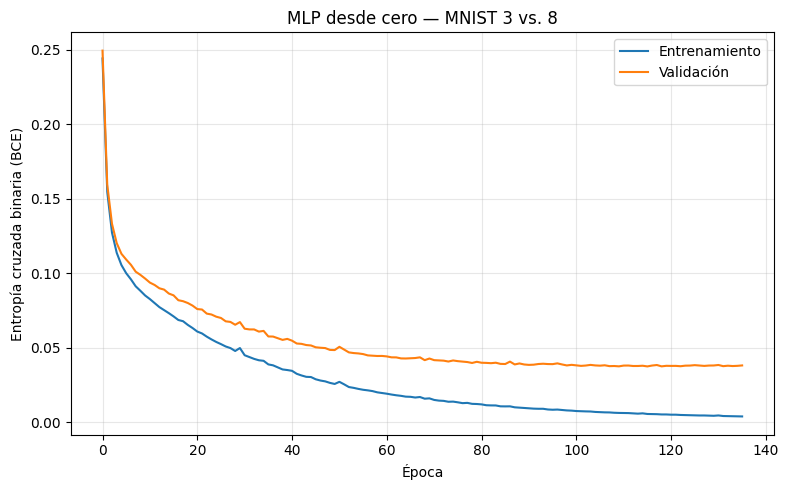

=== RESULTADOS EN TEST — MLP ===
accuracy       : 0.9900
sensibilidad   : 0.9893
especificidad  : 0.9907
f1             : 0.9897
auc            : 0.9990
precision      : 0.9902
Matriz de confusión [0, 1]:
[[1061   10]
 [  11 1013]]


In [2]:
"""
Perceptrón multicapa para la clasificación binaria de MNIST (dígitos 3 y 8).

Implementación desde cero utilizada en la etapa de validación
conceptual. Se utiliza BCE, entrenamiento por mini-lotes y parada temprana.
"""

import numpy as np
import matplotlib.pyplot as plt

from preparar_datos import (
    preparar_datos_mnist_binario,
    calcular_metricas,
    SEMILLA,
)


# =========================================================
# 1. PREPARACIÓN DE LOS DATOS
# =========================================================

np.random.seed(SEMILLA)

datos = preparar_datos_mnist_binario(
    formato="vector",
    etiquetas=(0, 1),
)

X_train, y_train = datos["train"]
X_val, y_val = datos["val"]
X_test, y_test = datos["test"]

y_train = np.asarray(y_train).reshape(-1, 1)
y_val = np.asarray(y_val).reshape(-1, 1)
y_test = np.asarray(y_test).reshape(-1, 1)

print("Información de las particiones:", datos["info"])
print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validación:   ", X_val.shape, y_val.shape)
print("Prueba:       ", X_test.shape, y_test.shape)


# =========================================================
# 2. IMPLEMENTACIÓN DEL PERCEPTRÓN MULTICAPA
# =========================================================

def relu(x):
    return np.maximum(0, x)


def derivada_relu(z):
    return (z > 0).astype(z.dtype)


def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))


class Capa:
    def __init__(self, entradas, neuronas, activacion):
        # Inicialización de He en las capas de la red
        self.W = np.random.randn(entradas, neuronas) * np.sqrt(2 / entradas)
        self.b = np.zeros((1, neuronas))
        self.activacion = activacion


arquitectura = [784, 128, 64, 1]  # Entrada, dos capas ocultas y salida
funciones_activacion = ["relu", "relu", "sigmoid"]

red_neuronal = [
    Capa(arquitectura[i], arquitectura[i + 1], funciones_activacion[i])
    for i in range(len(arquitectura) - 1)
]


def bce(y_pred, y_real):
    y_pred = np.clip(y_pred, 1e-7, 1 - 1e-7)
    return -np.mean(y_real * np.log(y_pred) + (1 - y_real) * np.log(1 - y_pred))


def forward_pass(X, red):
    salida = X
    for capa in red:
        z = salida @ capa.W + capa.b
        salida = relu(z) if capa.activacion == "relu" else sigmoid(z)
    return salida


def entrenamiento(X, Y, red, lr=0.01, batch_size=64):
    indices = np.random.permutation(len(X))

    for inicio in range(0, len(X), batch_size):
        idx = indices[inicio:inicio + batch_size]
        xb, yb = X[idx], Y[idx]

        # Propagación hacia adelante
        activaciones = [xb]
        preactivaciones = []
        for capa in red:
            z = activaciones[-1] @ capa.W + capa.b
            preactivaciones.append(z)
            activaciones.append(relu(z) if capa.activacion == "relu" else sigmoid(z))

        # Gradiente de BCE respecto de logits con salida sigmoide
        delta = activaciones[-1] - yb

        # Propagación hacia atrás y actualización de pesos
        for i in reversed(range(len(red))):
            capa = red[i]
            dW = activaciones[i].T @ delta / len(xb)
            db = np.mean(delta, axis=0, keepdims=True)

            if i > 0:
                delta_anterior = (delta @ capa.W.T) * derivada_relu(preactivaciones[i - 1])

            capa.W -= lr * dW
            capa.b -= lr * db

            if i > 0:
                delta = delta_anterior


# =========================================================
# 3. ENTRENAMIENTO Y PARADA TEMPRANA
# =========================================================

epocas = 1000
lr = 0.01
batch_size = 64
paciencia = 20

mejor_val_loss = np.inf
mejor_epoca = 0
contador = 0
mejores_pesos = None
train_losses, val_losses = [], []

for epoca in range(epocas):
    entrenamiento(X_train, y_train, red_neuronal, lr=lr, batch_size=batch_size)

    train_loss = bce(forward_pass(X_train, red_neuronal), y_train)
    val_loss = bce(forward_pass(X_val, red_neuronal), y_val)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if epoca == 0 or (epoca + 1) % 10 == 0:
        print(f"Época {epoca + 1:4d} | Train BCE: {train_loss:.5f} | Val BCE: {val_loss:.5f}")

    if val_loss < mejor_val_loss:
        mejor_val_loss = val_loss
        mejor_epoca = epoca + 1
        contador = 0
        mejores_pesos = [(c.W.copy(), c.b.copy()) for c in red_neuronal]
    else:
        contador += 1

    if contador >= paciencia:
        print(f"\nEarly stopping en época {epoca + 1}")
        break

for capa, (W, b) in zip(red_neuronal, mejores_pesos):
    capa.W = W.copy()
    capa.b = b.copy()

print(f"Mejor época: {mejor_epoca}")
print(f"Mejor Val BCE: {mejor_val_loss:.5f}")


# =========================================================
# 4. EVOLUCIÓN DE LA PÉRDIDA DE ENTRENAMIENTO Y VALIDACIÓN
# =========================================================

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Entrenamiento")
plt.plot(val_losses, label="Validación")
plt.xlabel("Época")
plt.ylabel("Entropía cruzada binaria (BCE)")
plt.title("MLP desde cero — MNIST 3 vs. 8")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# =========================================================
# 5. EVALUACIÓN SOBRE EL CONJUNTO DE PRUEBA
# =========================================================

from sklearn.metrics import precision_score, confusion_matrix

Ypred_test = forward_pass(X_test, red_neuronal)
predicciones_test = (Ypred_test >= 0.5).astype(int)

metricas_test = calcular_metricas(
    y_true=y_test.ravel(),
    y_pred=predicciones_test.ravel(),
    y_scores=Ypred_test.ravel(),
    clase_positiva=1,
)
precision = precision_score(y_test.ravel(), predicciones_test.ravel(), pos_label=1, zero_division=0)

print("=== RESULTADOS EN TEST — MLP ===")
for nombre, valor in metricas_test.items():
    print(f"{nombre:15s}: {valor:.4f}" if valor is not None else f"{nombre:15s}: N/A")
print(f"{'precision':15s}: {precision:.4f}")
print("Matriz de confusión [0, 1]:")
print(confusion_matrix(y_test.ravel(), predicciones_test.ravel(), labels=[0, 1]))



In [3]:
# =========================================================
# 6. DISTRIBUCIÓN DE CLASES EN EL CONJUNTO DE PRUEBA
# =========================================================

print("\nDistribución de clases en prueba:")
print("Total de imágenes:", len(y_test))
print("Dígito 3:", np.sum(y_test == 0))
print("Dígito 8:", np.sum(y_test == 1))



Distribución de clases en prueba:
Total de imágenes: 2095
Dígito 3: 1071
Dígito 8: 1024
